## Tommy Peer
tp0110@uah.edu

keyword: upsidedownhorse

https://github.com/upsidedownhorsegh

## Problem 1

Show the closed-form solution to the weighted least-squares problem.

Write the objective in matrix form, with $A$ the diagonal weight matrix ($A_{ii} = a^{(i)}$):

$$J(w) = \frac{1}{2}(y - Xw)^\top A (y - Xw) + \frac{\lambda}{2}w^\top w$$

Expand:

$$J(w) = \frac{1}{2}\left( y^\top A y - 2w^\top X^\top A y + w^\top X^\top A X w \right) + \frac{\lambda}{2}w^\top w$$

Take the gradient and set to zero:

$$\nabla_w J = -X^\top A y + X^\top A X w + \lambda w = 0$$

$$(X^\top A X + \lambda I)\, w = X^\top A y$$

$$\boxed{\hat{w} = (X^\top A X + \lambda I)^{-1} X^\top A y}$$

Setting $A = I$ recovers the ridge regression solution, so locally-weighted regression generalizes ridge — each point is weighted by $a^{(i)}$.

## Problem 2

Model (no intercept): $h_\theta(x) = \sigma(\theta^\top x) = \dfrac{1}{1+e^{-\theta^\top x}}$, with $\theta = [1.5, 2, 1]^\top$.

| $i$ | $x$ | $\theta^\top x$ | $h_\theta(x)$ | $y$ |
|---|---|---|---|---|
| 1 | (0,0,1) | 1 | 0.7311 | 0 |
| 2 | (0,1,0) | 2 | 0.8808 | 1 |
| 3 | (0,1,1) | 3 | 0.9526 | 1 |
| 4 | (1,0,0) | 1.5 | 0.8176 | 0 |

**Part 1 — Cost $J(\theta)$**

$$J(\theta) = -\frac{1}{N}\sum_i \left[ y^{(i)}\log(h) + (1-y^{(i)})\log(1-h) \right]$$

Per-example terms: $-1.3133,\ -0.1269,\ -0.0486,\ -1.7014$; sum $= -3.1902$.

$$J(\theta) = -\tfrac{1}{4}(-3.1902) = \mathbf{0.7975}$$

**Part 2 — Gradients**

$$\frac{\partial J}{\partial \theta_j} = \frac{1}{N}\sum_i (h_\theta(x^{(i)}) - y^{(i)})\, x_j^{(i)}$$

Errors $(h-y)$: $0.7311,\ -0.1192,\ -0.0474,\ 0.8176$.

$$\frac{\partial J}{\partial \theta_1} = \tfrac{1}{4}(0.8176) = \mathbf{0.2044}$$
$$\frac{\partial J}{\partial \theta_2} = \tfrac{1}{4}(-0.1192 - 0.0474) = \mathbf{-0.0417}$$
$$\frac{\partial J}{\partial \theta_3} = \tfrac{1}{4}(0.7311 - 0.0474) = \mathbf{0.1709}$$

**Part 3 — Update ($\eta = 1$):** $\theta_j \leftarrow \theta_j - \eta\,\frac{\partial J}{\partial \theta_j}$

$$\theta = [\,1.2956,\ 2.0417,\ 0.8291\,]^\top$$

## Problem 3

- **Purpose:** Logistic regression is a classification model (outputs a probability in [0,1] via the sigmoid for a categorical label); polynomial regression predicts a continuous value.
- **Form:** Polynomial regression fits a curve by adding powers of $x$ ($w_0 + w_1x + w_2x^2 + \dots$); logistic regression passes a linear combination $\theta^\top x$ through the sigmoid.
- **Loss:** Polynomial regression minimizes squared error (MSE); logistic regression minimizes cross-entropy / negative log-likelihood.
- **Output use:** Logistic regression thresholds the probability (e.g. 0.5) to assign a class; polynomial regression uses its output directly.

Summary: polynomial regression predicts *how much*; logistic regression predicts *how likely / which class*.[link text](https://)

## Problem 4

**1. Homoscedasticity violation.** Plot residuals vs. fitted values — a fan/cone shape (variance changing with $\hat{y}$) signals heteroscedasticity. Formal test: **Breusch–Pagan** (or White) test on the squared residuals.

**2. Normality-of-errors violation.** A **Q–Q plot** of residuals — departure from the 45° line (heavy tails, curved ends) signals non-normality. Formal test: **Shapiro–Wilk**.

**3. Multicollinearity (multiple regression).** **Variance Inflation Factor**, $\text{VIF}_j = \dfrac{1}{1 - R_j^2}$; VIF > 5–10 flags collinearity. Also: high pairwise correlations or a near-singular $X^\top X$.

**Bonus 4 — dependent (autocorrelated) errors.** **Durbin–Watson test**: $d = \dfrac{\sum_{t=2}^N (\hat{e}_t - \hat{e}_{t-1})^2}{\sum_{t=1}^N \hat{e}_t^2}$, range 0–4; $d \approx 2$ means no autocorrelation, $d < 2$ positive, $d > 2$ negative.

**Bonus 5 — non-normal errors.** **Jarque–Bera test**: $JB = \dfrac{N}{6}\left(S^2 + \dfrac{(K-3)^2}{4}\right)$ with skewness $S$ and kurtosis $K$; under normality $JB \sim \chi^2_2$, large values reject normality.

## Problem 5

Shape: (9568, 5)
Columns: ['AT', 'V', 'AP', 'RH', 'PE']
      AT      V       AP     RH      PE
0   8.34  40.77  1010.84  90.01  480.48
1  23.64  58.49  1011.40  74.20  445.75
2  29.74  56.90  1007.15  41.91  438.76
3  19.07  49.69  1007.22  76.79  453.09
4  11.80  40.66  1017.13  97.20  464.43


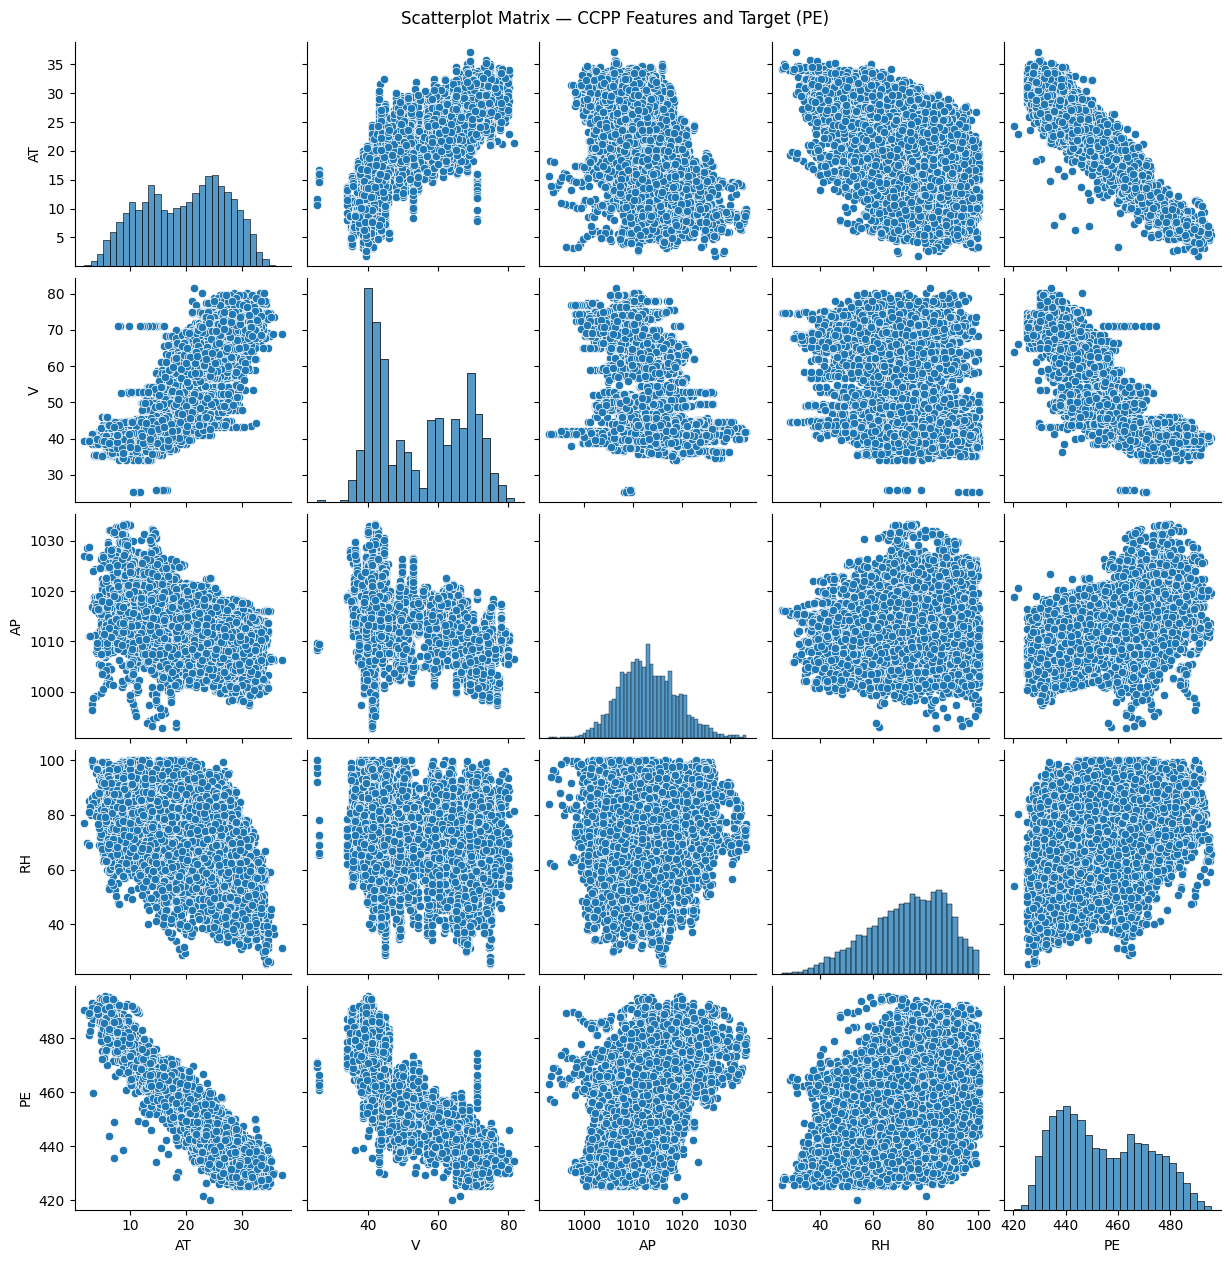

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.head())

# Sub-task 1: scatterplot matrix showing correlation among features and with target
sns.pairplot(df)
plt.suptitle("Scatterplot Matrix — CCPP Features and Target (PE)", y=1.01)
plt.show()

In [ ]:
import torch
import numpy as np

torch.manual_seed(0)

class CauchyRegression:
    def __init__(self, c=1.0, lr=0.1, epochs=2000):
        self.c = c
        self.lr = lr
        self.epochs = epochs
        self.w = None          # slopes (standardized space)
        self.b = None          # bias
        self.mu = None         # feature means
        self.sigma = None      # feature stds
        self.loss_history = []

    def _cauchy_loss(self, resid):
        # l = (c^2 / 2) * log(1 + (resid/c)^2), averaged over samples
        return (self.c**2 / 2 * torch.log(1 + (resid / self.c)**2)).mean()

    def fit(self, X, y):
        X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
        y = torch.as_tensor(np.asarray(y), dtype=torch.float32).reshape(-1)

        # standardize features (store stats to reuse in predict / coefficients)
        self.mu = X.mean(dim=0)
        self.sigma = X.std(dim=0)
        Xs = (X - self.mu) / self.sigma

        D = Xs.shape[1]
        self.w = torch.zeros(D, requires_grad=True)
        self.b = torch.tensor([y.mean().item()], requires_grad=True)  # start at mean(y)

        optimizer = torch.optim.Adam([self.w, self.b], lr=self.lr)
        self.loss_history = []
        for _ in range(self.epochs):
            optimizer.zero_grad()
            y_pred = Xs @ self.w + self.b
            loss = self._cauchy_loss(y - y_pred)
            loss.backward()
            optimizer.step()
            self.loss_history.append(loss.item())
        return self

    def predict(self, X):
        X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
        Xs = (X - self.mu) / self.sigma
        with torch.no_grad():
            return (Xs @ self.w + self.b).numpy()

    def coefficients(self):
        # transform standardized coeffs back to original feature scale
        w = self.w.detach()
        b = self.b.detach()
        w_orig = (w / self.sigma).numpy()
        b_orig = (b - (w * self.mu / self.sigma).sum()).item()
        return b_orig, w_orig

    def final_loss(self):
        return self.loss_history[-1]


# ---- Sub-task 2/3/4: fit and report ----
X = df[["AT", "V", "AP", "RH"]].values
y = df["PE"].values

model = CauchyRegression(c=1.0, lr=0.1, epochs=2000)
model.fit(X, y)

b0, slopes = model.coefficients()
print("Intercept (w0):", round(b0, 4))
for name, w in zip(["AT", "V", "AP", "RH"], slopes):
    print(f"  w_{name}: {round(float(w), 4)}")

print("Final (average) Cauchy loss:", round(model.final_loss(), 6))

Intercept (w0): 511.5592
  w_AT: -2.0826
  w_V: -0.2358
  w_AP: 0.0074
  w_RH: -0.1549
Final (average) Cauchy loss: 1.134774


In [ ]:
import numpy as np
np.random.seed(0)

n_boot = 100
n = len(y)
boot_coefs = []

for b in range(n_boot):
    idx = np.random.choice(n, size=n, replace=True)
    m = CauchyRegression(c=1.0, lr=0.1, epochs=600)
    m.fit(X[idx], y[idx])
    b0_b, slopes_b = m.coefficients()
    boot_coefs.append([b0_b, *slopes_b])

boot_coefs = np.array(boot_coefs)

names = ["Intercept", "AT", "V", "AP", "RH"]
print("95% Confidence Intervals (bootstrap, n=100):")
for j, name in enumerate(names):
    lo, hi = np.percentile(boot_coefs[:, j], [2.5, 97.5])
    print(f"  {name:10s}: [{lo:.4f}, {hi:.4f}]")

95% Confidence Intervals (bootstrap, n=100):
  Intercept : [460.9814, 539.3784]
  AT        : [-2.1219, -2.0114]
  V         : [-0.2626, -0.2160]
  AP        : [-0.0193, 0.0571]
  RH        : [-0.1658, -0.1395]


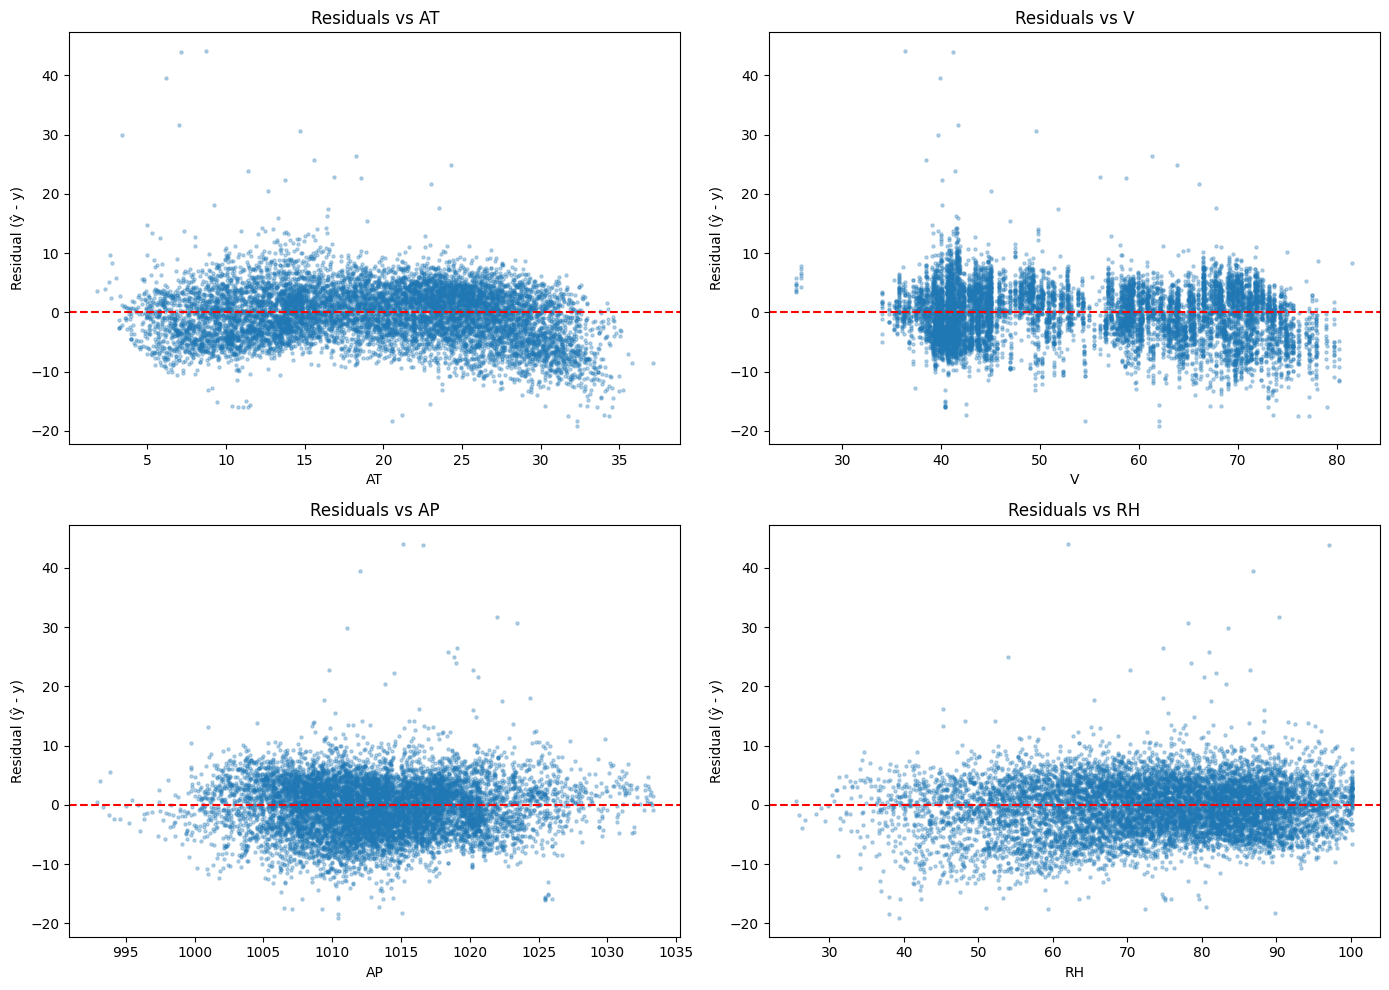

In [ ]:
import matplotlib.pyplot as plt

y_pred = model.predict(X)
residuals = y_pred - y        # ŷ - y, as the spec specifies

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for ax, feat in zip(axs.ravel(), ["AT", "V", "AP", "RH"]):
    ax.scatter(df[feat], residuals, s=5, alpha=0.3)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel(feat)
    ax.set_ylabel("Residual (ŷ - y)")
    ax.set_title(f"Residuals vs {feat}")
plt.tight_layout()
plt.show()

## Problem 6

### Dataset: Phishing Websites (UCI id 327)

**Goal:** classify whether a website is a *phishing* site or *legitimate*, from 30 features extracted from its URL, domain, and HTML/JavaScript behavior.

**Features (30 total)**, each encoded as -1 (phishing-like), 0 (suspicious), or 1 (legitimate-like). They fall into groups:
- **Address-bar based:** having_ip_address, url_length, shortining_service, having_at_symbol, double_slash_redirecting, prefix_suffix, having_sub_domain, sslfinal_state, domain_registration_length, favicon, port, https_token
- **Abnormal / content based:** request_url, url_of_anchor, links_in_tags, sfh (server form handler), submitting_to_email, abnormal_url
- **HTML/JavaScript based:** redirect, on_mouseover, rightclick, popupwindow, iframe
- **Domain based:** age_of_domain, dnsrecord, web_traffic, page_rank, google_index, links_pointing_to_page, statistical_report

**Label (`result`):** -1 = phishing, 1 = legitimate (remapped to 1 = phishing / 0 = legitimate for training, so the positive class is the one we want to detect).

**Class balance:** 6157 legitimate (55.7%) vs 4898 phishing (44.3%) — mildly imbalanced.

In [ ]:
!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo
import pandas as pd

phishing = fetch_ucirepo(id=327)
Xdf = phishing.data.features
ydf = phishing.data.targets

print("Feature matrix shape:", Xdf.shape)
print("Target shape:", ydf.shape)
print("\nFeature columns:")
print(list(Xdf.columns))
print("\nTarget column:", list(ydf.columns))
print("\nTarget value counts:")
print(ydf.iloc[:, 0].value_counts())

Xdf.head()

Feature matrix shape: (11055, 30)
Target shape: (11055, 1)

Feature columns:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']

Target column: ['result']

Target value counts:
result
 1    6157
-1    4898
Name: count, dtype: int64


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [ ]:
import torch
import numpy as np
from sklearn.model_selection import train_test_split

# features are already in {-1,0,1}; remap target so phishing = 1 (positive class)
X_all = Xdf.values.astype(np.float32)
y_all = (ydf.iloc[:, 0].values == -1).astype(np.float32)   # 1 = phishing

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=42, stratify=y_all)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (8291, 30)  Test: (2764, 30)


In [ ]:
torch.manual_seed(0)

class LogisticRegression:
    """Logistic regression: sigmoid + cross-entropy, trained by mini-batch SGD."""
    def __init__(self, lr=0.1, epochs=100, batch_size=64):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.w = None
        self.b = None
        self.loss_history = []

    def _bce(self, p, y):
        eps = 1e-7                      # avoid log(0)
        return -torch.mean(y*torch.log(p+eps) + (1-y)*torch.log(1-p+eps))

    def fit(self, X, y):
        X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
        y = torch.as_tensor(np.asarray(y), dtype=torch.float32).reshape(-1)
        n, d = X.shape
        self.w = torch.zeros(d, requires_grad=True)
        self.b = torch.zeros(1, requires_grad=True)
        optimizer = torch.optim.SGD([self.w, self.b], lr=self.lr)

        for _ in range(self.epochs):
            perm = torch.randperm(n)                    # shuffle each epoch
            for i in range(0, n, self.batch_size):
                idx = perm[i:i+self.batch_size]
                optimizer.zero_grad()
                p = torch.sigmoid(X[idx] @ self.w + self.b)
                loss = self._bce(p, y[idx])
                loss.backward()
                optimizer.step()
            with torch.no_grad():                        # record full-data loss
                p_full = torch.sigmoid(X @ self.w + self.b)
                self.loss_history.append(self._bce(p_full, y).item())
        return self

    def predict_proba(self, X):
        X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
        with torch.no_grad():
            return torch.sigmoid(X @ self.w + self.b).numpy()

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


clf = LogisticRegression(lr=0.1, epochs=100, batch_size=64)
clf.fit(X_train, y_train)
print("Final training loss:", round(clf.loss_history[-1], 4))

Final training loss: 0.1808


Test-set metrics (positive class = phishing):
  Accuracy:  0.9313
  Precision: 0.9412
  Recall:    0.9012
  F1 score:  0.9208
  ROC-AUC:   0.9786

Confusion matrix:
           pred_legit  pred_phish
true_legit     1470         69
true_phish      121       1104


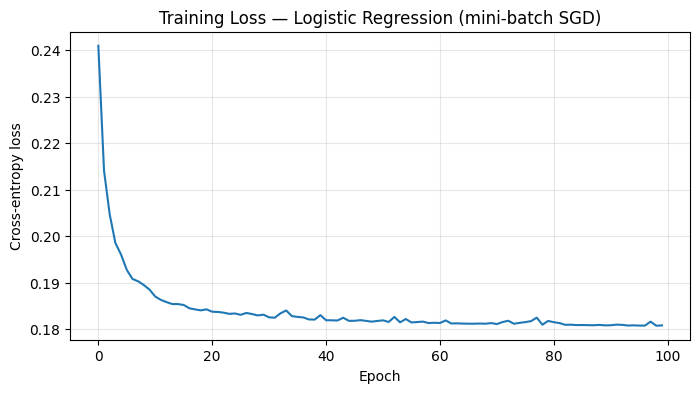

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)
import matplotlib.pyplot as plt
import numpy as np

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)

print("Test-set metrics (positive class = phishing):")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"  F1 score:  {f1_score(y_test, y_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix:")
print("           pred_legit  pred_phish")
print(f"true_legit    {cm[0,0]:5d}      {cm[0,1]:5d}")
print(f"true_phish    {cm[1,0]:5d}      {cm[1,1]:5d}")

# loss curve
plt.figure(figsize=(8,4))
plt.plot(clf.loss_history)
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Training Loss — Logistic Regression (mini-batch SGD)")
plt.grid(alpha=0.3); plt.show()

### Results & Discussion

| Metric | Value |
|---|---|
| Accuracy | 0.9313 |
| Precision | 0.9412 |
| Recall | 0.9012 |
| F1 | 0.9208 |
| ROC-AUC | 0.9786 |

**Confusion matrix:** 1470 legitimate correctly passed, 69 legitimate wrongly flagged (false positives); 1104 phishing caught, **121 phishing missed (false negatives).**

**Interpretation for phishing detection:**
- **Recall = 0.90** is the security-critical metric: ~1 in 10 phishing sites slips past the model (the 121 false negatives). Each miss is a user potentially attacked, so in a real deployment we might lower the decision threshold below 0.5 to raise recall at the cost of more false positives.
- **Precision = 0.94:** when the model flags a site as phishing it is right 94% of the time, so legitimate sites are rarely blocked (69 false positives).
- **ROC-AUC = 0.979** shows the model ranks phishing above legitimate almost perfectly, independent of threshold.
- **Class balance (56/44)** is mild, so accuracy is a trustworthy headline here; on a severely imbalanced set we would rely on F1/recall and the confusion matrix instead.

## AI Statement

AI was used In this for the following tasks:
- Walking through each problem, step by step, so that I understand how to complete it and can learn with efficiency.
- Placing the answers that I worked out into submittable block form for colab, mainly because I am not familiar with the language that makes the equations comprehensive
- Programming help and datasetfnding/work


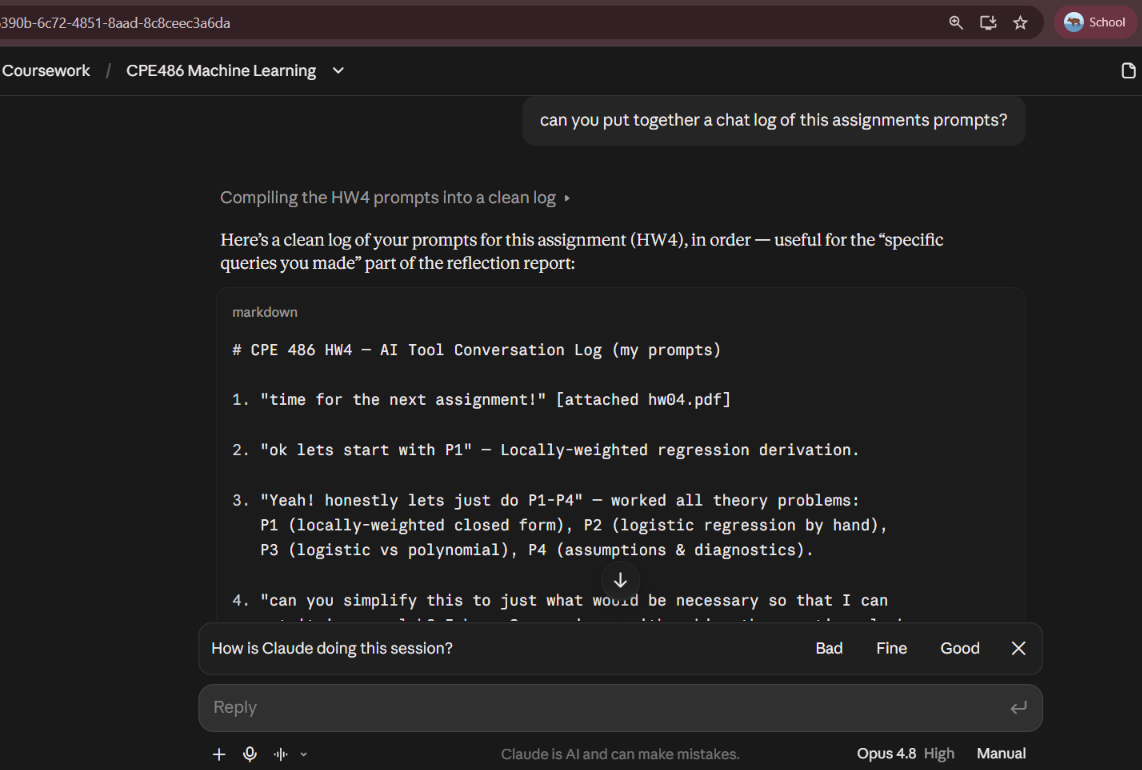
